In [1]:
# Cell 1 - run information (required)
%pip install -q open_clip_torch==3.3.0 lpips==0.1.4 torchmetrics==1.9.0 torch-fidelity==0.4.0 "diffusers @ git+https://github.com/huggingface/diffusers.git@6dcb307d1249daa30de102570aeba6eb40ea351a"
import os, subprocess, sys, random, numpy as np, torch
from importlib import metadata as _md
try:                                    # Colab: the repo clone may live in Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass
# Commit of the GitHub repo these notebooks belong to. Without a git clone, copy the short hash shown
# on the GitHub repo page (e.g. "a1b2c3d") and paste it here.
COMMIT_HASH = "a1f01f8"
# If a git clone of the repo exists (folder with .git), the commit is read from it instead.
_candidates = [os.environ.get("REPO_DIR", ""), "/content/drive/MyDrive/data266-lab2-team42",
               "/content/data266-lab2-team42", os.getcwd()]
REPO_DIR = next((d for d in _candidates if d and os.path.isdir(os.path.join(d, ".git"))), None)
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if REPO_DIR:
    os.chdir(REPO_DIR)
    commit = subprocess.run(["git", "-c", "safe.directory=*", "rev-parse", "--short", "HEAD"],
                            capture_output=True, text=True).stdout.strip()
elif COMMIT_HASH:
    commit = COMMIT_HASH + " (from GitHub page)"
else:
    commit = "MISSING"
    print("WARNING: paste the commit hash from your GitHub repo page into COMMIT_HASH and re-run this cell.")
print({"commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})

def _version(pkg):
    try:
        return _md.version(pkg)
    except _md.PackageNotFoundError:
        return "not installed"
print({p: _version(p) for p in ["diffusers", "transformers", "peft", "accelerate", "open_clip_torch",
                                "lpips", "torchmetrics", "torch-fidelity", "huggingface_hub"]})

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive
{'commit': 'a1f01f8 (from GitHub page)', 'python': '3.13.16', 'torch': '2.14.1+cu130', 'gpu': 'Tesla T4', 'seed': 266}
{'diffusers': '0.42.0.dev0', 'transformers': '5.22.1', 'peft': '0.21.2', 'accelerate': '1.15.0', 'open_clip_torch': '3.3.0', 'lpips': '0.1.4', 'torchmetrics': '1.9.0', 'torch-fidelity': '0.4.0', 'huggingface_hub': '1.33.0'}


# Part 2 (2/2): evaluation, safety and release

Recomputes every Part 2 number from the artifacts written by `p2_finetune.ipynb` (prepared split,
frozen prompts, LoRA adapters, 120 generated images). **No training or image generation happens here**,
so it runs on a Colab T4 in a few minutes and also works on a CPU runtime (slower).

| Section | Lab item |
|---|---|
| Data audit, dataset description, licences | 2.1, C4 |
| Side-by-side grids (8 prompts) | 2.3.3 |
| CLIP score, LPIPS diversity, KID (in-domain) | 2.4 primary / secondary |
| NSFW output filter | 2.4.2, C4 |
| Blinded human evaluation (25 unique pairs, 3 raters) | 2.4 human evaluation |
| Memorization check (generated vs training) | 2.4.2, C4 |
| Failure modes | 2.4.1 |
| One results table, final-run choice | C2.1, 2.4.1 |
| Model card, image dataset with metadata | 2.2.3, 2.3.3, C3.2 |

Run with **Runtime → Restart and run all**. Uploads to Hugging Face only happen when `UPLOAD_TO_HUB = True`.

In [2]:
# Configuration
import json, gc, time, shutil, textwrap, warnings
from pathlib import Path
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display, Image as IPyImage
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)

PROJECT_DIR = Path(os.environ.get("P2_PROJECT_DIR", "/content/drive/MyDrive/Sem3/DATA266/Lab2/Part2"))
if str(PROJECT_DIR).startswith("/content/drive") and not PROJECT_DIR.exists():
    from google.colab import drive
    drive.mount("/content/drive")
assert PROJECT_DIR.exists(), f"Project folder not found: {PROJECT_DIR}"

OLD_PREFIX = "/content/drive/MyDrive/Sem3/DATA266/Lab2/Part2"   # absolute paths stored in earlier CSVs
def resolve(p):
    p = str(p)
    return PROJECT_DIR / p[len(OLD_PREFIX):].lstrip("/") if p.startswith(OLD_PREFIX) else Path(p)

TRAIN_DIR = PROJECT_DIR / "data/prepared/train"
TEST_DIR = PROJECT_DIR / "data/prepared/test"
MODEL_DIR = PROJECT_DIR / "models"
GENERATED_DIR = PROJECT_DIR / "outputs/generated"
RESULTS_DIR = PROJECT_DIR / "results"
FIG_DIR = RESULTS_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
PROMPT_FILE = PROJECT_DIR / "prompts/fixed_20_prompts.json"

MODEL_NAME = "stable-diffusion-v1-5/stable-diffusion-v1-5"
DATASET_NAME = "lambdalabs/naruto-blip-captions"
MODELS = ["base", "lora_rank4", "lora_rank16"]
FINAL_MODEL = "lora_rank16"            # the run used for the human evaluation and the model card
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

HF_USERNAME = "Anushka1202"
RANK4_REPO = f"{HF_USERNAME}/data266-lab2-part2-lora-rank4"
RANK16_REPO = f"{HF_USERNAME}/data266-lab2-part2-lora-rank16"
UNFILTERED_DATASET_REPO = f"{HF_USERNAME}/data266-lab2-part2-generated-images"
SAFE_DATASET_REPO = f"{HF_USERNAME}/data266-lab2-part2-generated-images-safe"
UPLOAD_TO_HUB = True                    # True: push model cards + cleaned image dataset
CLEAN_UNFILTERED_REPO = True            # True: delete NSFW-flagged files from the unfiltered dataset repo

def save_and_show(fig, name, width=1000):
    """Save a full-resolution PNG and embed a small JPEG preview (keeps the saved notebook light)."""
    png = FIG_DIR / f"{name}.png"
    fig.savefig(png, dpi=110, bbox_inches="tight"); plt.close(fig)
    preview = Image.open(png).convert("RGB"); preview.thumbnail((1400, 4000))
    jpg = FIG_DIR / f"{name}_preview.jpg"; preview.save(jpg, quality=80)
    display(IPyImage(filename=str(jpg), width=width))
    print("saved:", png)

def to_markdown(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(str(r[c]) for c in cols) + " |" for _, r in df.iterrows()]
    return "\n".join(lines)

print({"project_dir": str(PROJECT_DIR), "device": DEVICE, "final_model": FINAL_MODEL,
       "upload_to_hub": UPLOAD_TO_HUB})

{'project_dir': '/content/drive/MyDrive/Sem3/DATA266/Lab2/Part2', 'device': 'cuda', 'final_model': 'lora_rank16', 'upload_to_hub': True}


In [3]:
# Load the frozen prompts, generation metadata and training summary written by p2_finetune.ipynb
prompt_rows = json.loads(PROMPT_FILE.read_text())
prompts = pd.DataFrame(prompt_rows)
assert len(prompts) == 20
assert prompts["category"].value_counts().to_dict() == {"in_domain": 10, "out_of_domain": 5, "compositional": 5}

cleaning_report = json.loads((RESULTS_DIR / "data_cleaning_report.json").read_text())
train_paths = sorted(TRAIN_DIR.glob("*.png"))
test_paths = sorted(TEST_DIR.glob("*.png"))
assert len(train_paths) == cleaning_report["train_count"] and len(test_paths) == cleaning_report["test_count"]
train_meta = pd.read_json(TRAIN_DIR / "metadata.jsonl", lines=True)
test_meta = pd.read_json(TEST_DIR / "metadata.jsonl", lines=True)

in_domain_prompts = set(prompts.loc[prompts.category == "in_domain", "prompt"])
assert in_domain_prompts <= set(test_meta["text"]), "in-domain prompts must be held-out test captions"
captions_also_in_train = sorted(in_domain_prompts & set(train_meta["text"]))

gen = pd.read_csv(RESULTS_DIR / "generation_metadata.csv")
gen["path"] = gen["path"].map(lambda p: str(resolve(p)))
gen["file_name"] = gen["model"] + "/" + gen["path"].map(lambda p: Path(p).name)
assert gen.groupby("model").size().to_dict() == {m: 40 for m in MODELS}
assert all(Path(p).exists() for p in gen["path"])

training_summary = pd.read_csv(RESULTS_DIR / "training_summary.csv")

print(json.dumps(cleaning_report, indent=2))
print("Sampler settings shared by all 120 images:",
      gen[["steps", "guidance_scale"]].drop_duplicates().to_dict("records"), "| seeds:", sorted(gen.seed.unique()))
print("All 10 in-domain prompts are held-out test captions: True")
print("In-domain prompts whose exact caption text also occurs in the training set:", len(captions_also_in_train))
display(gen.groupby(["model", "category"]).size().unstack())
display(training_summary)

{
  "dataset": "lambdalabs/naruto-blip-captions",
  "original_count": 1221,
  "usable_unique_count": 1221,
  "removed_corrupt": 0,
  "removed_duplicate": 0,
  "train_count": 1098,
  "test_count": 123,
  "split_seed": 266,
  "resolution": [
    512,
    512
  ]
}
Sampler settings shared by all 120 images: [{'steps': 40, 'guidance_scale': 7.5}] | seeds: [np.int64(0), np.int64(1)]
All 10 in-domain prompts are held-out test captions: True
In-domain prompts whose exact caption text also occurs in the training set: 2


category,compositional,in_domain,out_of_domain
model,,,
base,10,20,10
lora_rank16,10,20,10
lora_rank4,10,20,10


,run,rank,trainable_parameters,learning_rate,steps,batch_size,training_seconds,gpu_hours,peak_gpu_memory_mib,peak_gpu_memory_gib
0,lora_rank4,4,797184,0.0001,1500,1,2921.444178,0.811512,6301,6.153320
1,lora_rank16,16,3188736,0.0001,1500,1,2907.956229,0.807766,6323,6.174805


## 2.1 Data audit and dataset description

The training notebook removed corrupt images and **exact** duplicates (SHA-256 of pixels). This cell
re-opens every prepared image with truncated-image loading switched off, and looks for **near**
duplicates (64-bit difference hash, Hamming distance ≤ 5) inside the training set and between the test
and training sets. The split is not changed (the adapters are already trained on it); near-duplicates
are reported as a limitation because they make KID and the memorization check slightly optimistic.

{
  "prepared_images_failing_strict_decode": 0,
  "near_dup_threshold_bits": 5,
  "test_images_with_near_duplicate_in_train": 1,
  "near_duplicate_pairs_within_train": 0,
  "captions": 1221,
  "distinct_caption_share": 0.792,
  "caption_words_mean": 8.93,
  "caption_words_min_max": [
    6,
    41
  ],
  "share_captions_male_terms": 0.588,
  "share_captions_female_terms": 0.206,
  "dataset_license_on_hub": "not stated on the Hub card",
  "base_model_license_on_hub": "creativeml-openrail-m"
}

Dataset: 1221 captioned images from lambdalabs/naruto-blip-captions; 0 corrupt and 0 exact duplicates removed; 1098 train / 123 test (seed 266), 512x512.
Captions average 8.93 words; 59% mention a man/boy vs 21% a woman/girl.


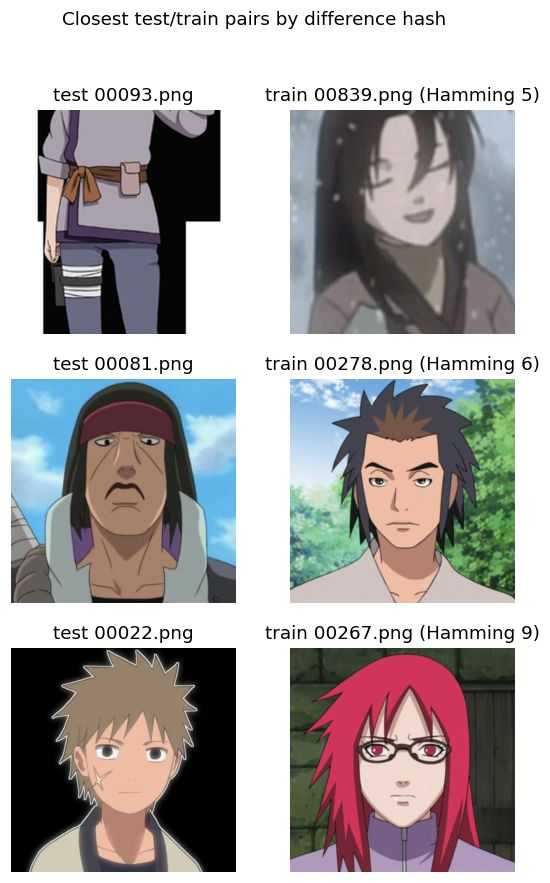

saved: /content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/results/figures/data_near_duplicates.png


In [4]:
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = False

def strict_ok(p):
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            im.load()
        return im.size == (512, 512)
    except Exception:
        return False

bad = [p.name for p in train_paths + test_paths if not strict_ok(p)]

def dhash_bits(p, size=8):
    g = np.asarray(Image.open(p).convert("L").resize((size + 1, size), Image.Resampling.LANCZOS), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).flatten()

NEAR_DUP_BITS = 5
H_train = np.stack([dhash_bits(p) for p in train_paths])
H_test = np.stack([dhash_bits(p) for p in test_paths])
ham_test_train = (H_test[:, None, :] != H_train[None, :, :]).sum(-1)
ham_train = (H_train[:, None, :] != H_train[None, :, :]).sum(-1)
iu = np.triu_indices(len(train_paths), 1)

caps = pd.concat([train_meta.assign(split="train"), test_meta.assign(split="test")], ignore_index=True)
n_words = caps["text"].str.split().str.len()
male = caps["text"].str.contains(r"\b(?:man|men|boy|boys|guy)\b", case=False, regex=True)
female = caps["text"].str.contains(r"\b(?:woman|women|girl|girls|lady)\b", case=False, regex=True)

from huggingface_hub import HfApi
api = HfApi()
def hub_license(repo_id, repo_type):
    try:
        info = api.dataset_info(repo_id) if repo_type == "dataset" else api.model_info(repo_id)
        lic = info.card_data.get("license") if info.card_data else None
        return lic or "not stated on the Hub card"
    except Exception as e:
        return f"lookup failed ({type(e).__name__})"

audit = {
    "prepared_images_failing_strict_decode": len(bad),
    "near_dup_threshold_bits": NEAR_DUP_BITS,
    "test_images_with_near_duplicate_in_train": int((ham_test_train.min(1) <= NEAR_DUP_BITS).sum()),
    "near_duplicate_pairs_within_train": int((ham_train[iu] <= NEAR_DUP_BITS).sum()),
    "captions": int(len(caps)),
    "distinct_caption_share": round(caps["text"].nunique() / len(caps), 3),
    "caption_words_mean": round(float(n_words.mean()), 2),
    "caption_words_min_max": [int(n_words.min()), int(n_words.max())],
    "share_captions_male_terms": round(float(male.mean()), 3),
    "share_captions_female_terms": round(float(female.mean()), 3),
    "dataset_license_on_hub": hub_license(DATASET_NAME, "dataset"),
    "base_model_license_on_hub": hub_license(MODEL_NAME, "model"),
}
dataset_description = {
    "dataset": DATASET_NAME,
    "summary": "Naruto anime frames with automatically generated BLIP captions, resized to 512x512.",
    "cleaning_report": cleaning_report,
    "audit": audit,
    "limitations": [
        "Single copyrighted anime domain: the model learns one style and is not representative of general images.",
        "BLIP captions are short and generic, so fine details, character identity and relationships are rarely described.",
        "Caption gender skew (male vs female terms, see audit) can carry over into generations.",
        "Near-duplicate frames from the same scenes exist, and some cross the train/test split (see audit).",
    ],
    "license_note": ("Naruto characters are copyrighted. The adapters and generated images are for "
                     "non-commercial academic research only; the base model is under the CreativeML OpenRAIL-M licence."),
}
(RESULTS_DIR / "dataset_description_v2.json").write_text(json.dumps(dataset_description, indent=2))

print(json.dumps(audit, indent=2))
print(f"\nDataset: {cleaning_report['original_count']} captioned images from {DATASET_NAME}; "
      f"{cleaning_report['removed_corrupt']} corrupt and {cleaning_report['removed_duplicate']} exact duplicates removed; "
      f"{cleaning_report['train_count']} train / {cleaning_report['test_count']} test (seed {cleaning_report['split_seed']}), 512x512.")
print(f"Captions average {audit['caption_words_mean']} words; {audit['share_captions_male_terms']:.0%} mention a man/boy "
      f"vs {audit['share_captions_female_terms']:.0%} a woman/girl.")

pairs = np.dstack(np.unravel_index(np.argsort(ham_test_train, axis=None)[:3], ham_test_train.shape))[0]
fig, ax = plt.subplots(3, 2, figsize=(6, 9))
for r, (i, j) in enumerate(pairs):
    ax[r, 0].imshow(Image.open(test_paths[i])); ax[r, 0].set_title(f"test {test_paths[i].name}")
    ax[r, 1].imshow(Image.open(train_paths[j])); ax[r, 1].set_title(f"train {train_paths[j].name} (Hamming {ham_test_train[i, j]})")
    ax[r, 0].axis("off"); ax[r, 1].axis("off")
fig.suptitle("Closest test/train pairs by difference hash")
save_and_show(fig, "data_near_duplicates", width=520)

## 2.3 Side-by-side grids: base vs run 1 (LoRA r4) vs run 2 (LoRA r16)

Eight prompts (4 in-domain, 2 out-of-domain, 2 compositional), seed 0, identical sampler settings.

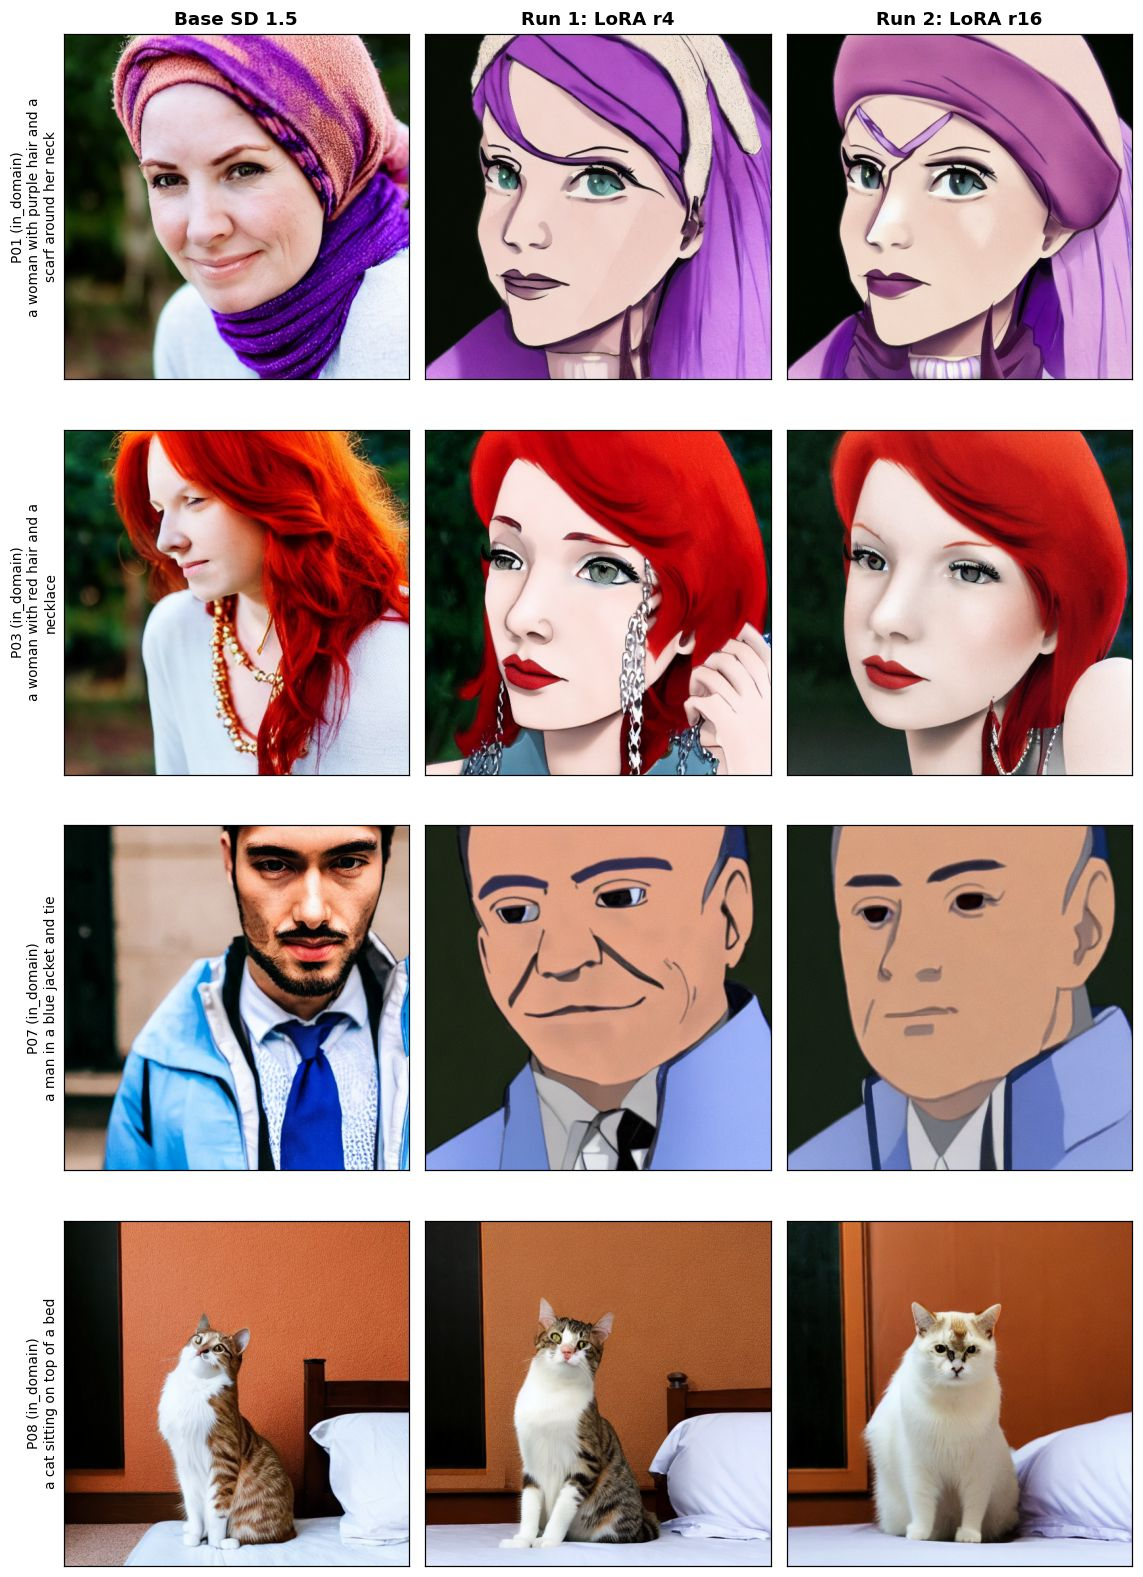

saved: /content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/results/figures/grid_base_r4_r16_part1.png


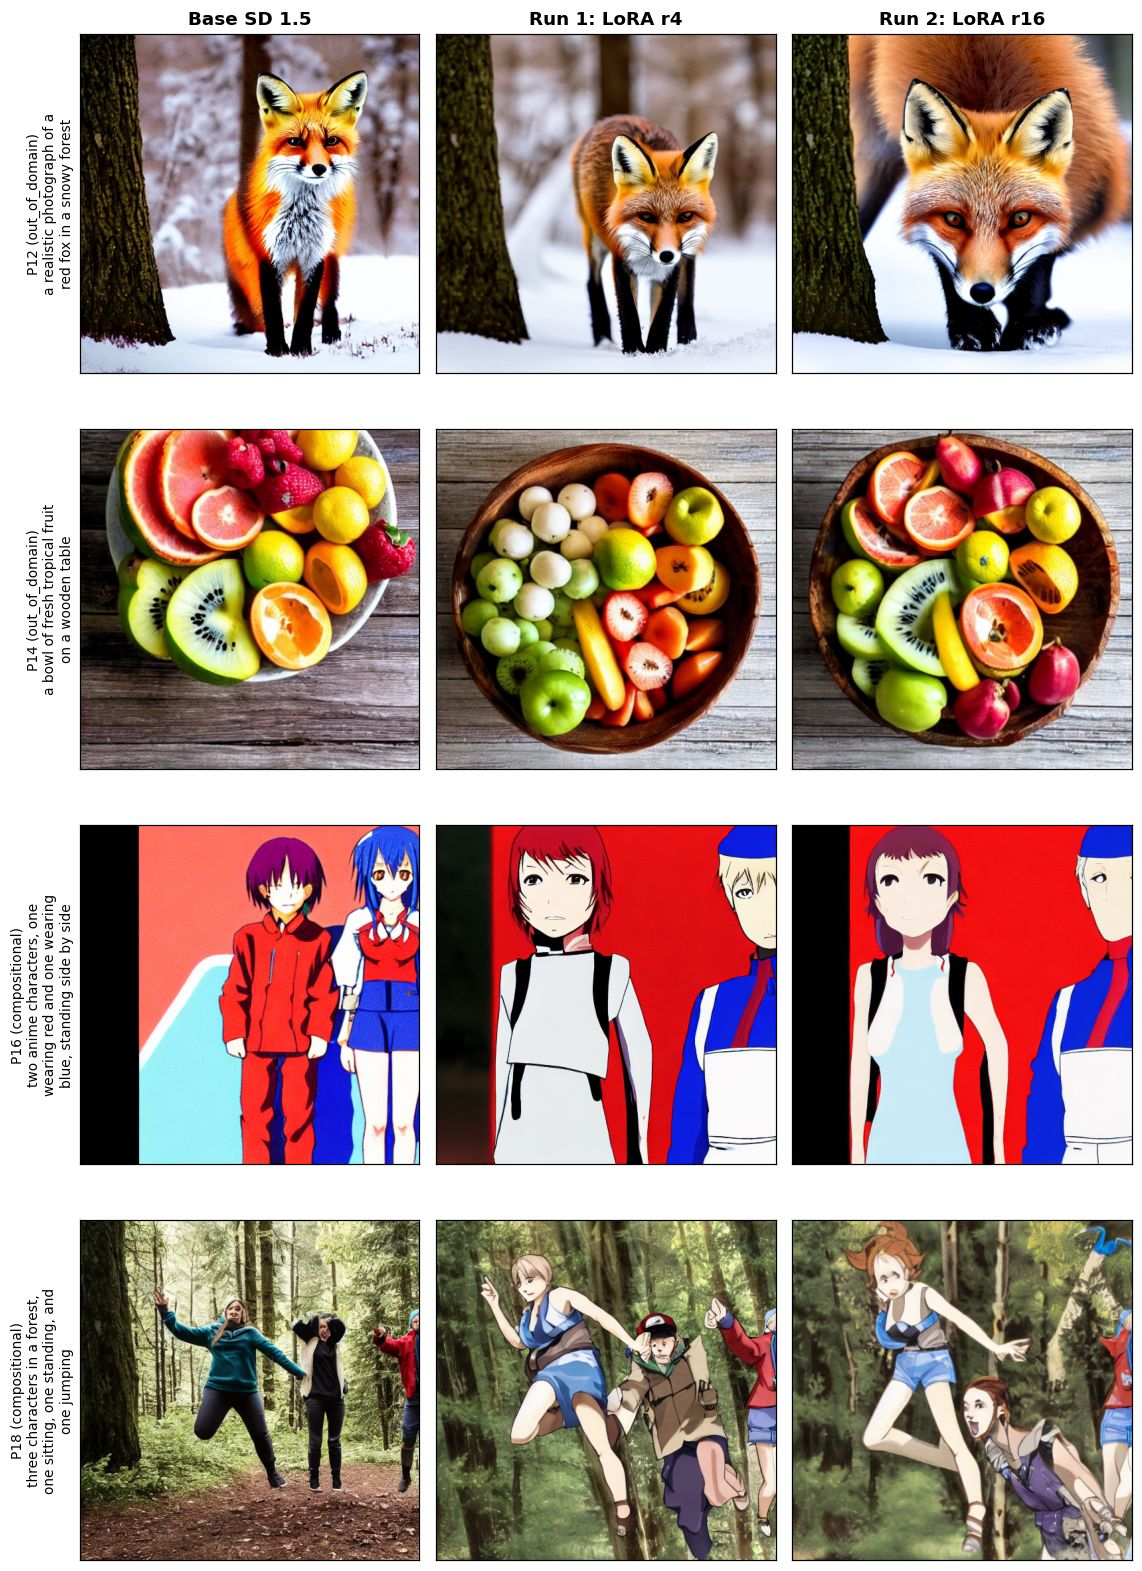

saved: /content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/results/figures/grid_base_r4_r16_part2.png


In [5]:
GRID_PROMPTS = ["P01", "P03", "P07", "P08", "P12", "P14", "P16", "P18"]
COLUMN_TITLES = {"base": "Base SD 1.5", "lora_rank4": "Run 1: LoRA r4", "lora_rank16": "Run 2: LoRA r16"}
prompt_text = prompts.set_index("prompt_id")["prompt"].to_dict()
prompt_cat = prompts.set_index("prompt_id")["category"].to_dict()

for part, ids in enumerate([GRID_PROMPTS[:4], GRID_PROMPTS[4:]], start=1):
    fig, ax = plt.subplots(len(ids), 3, figsize=(10.5, 3.7 * len(ids)))
    for r, pid in enumerate(ids):
        for c, m in enumerate(MODELS):
            ax[r, c].imshow(Image.open(GENERATED_DIR / m / f"{pid}_seed0.png"))
            ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
            if r == 0:
                ax[r, c].set_title(COLUMN_TITLES[m], fontsize=12, fontweight="bold")
        ax[r, 0].set_ylabel(f"{pid} ({prompt_cat[pid]})\n" + textwrap.fill(prompt_text[pid], 30), fontsize=9)
    fig.tight_layout()
    save_and_show(fig, f"grid_base_r4_r16_part{part}")

## 2.4 Automatic metrics

* **CLIP score** (primary): cosine similarity between the prompt and the image, OpenCLIP ViT-B/32 (OpenAI weights), all 40 images per model.
* **LPIPS diversity** (secondary): AlexNet LPIPS distance between the seed-0 and seed-1 images of each prompt (higher = more diverse).
* **KID** (primary, lower is better): the 20 in-domain generations per model against **all 123 held-out test images**,
  100 random subsets of 10, so the ± value is a real spread. With only 20 generated images KID is still noisy.

In [6]:
import open_clip, lpips

clip_model, _, clip_preprocess = open_clip.create_model_and_transforms("ViT-B-32", pretrained="openai", device=DEVICE)
clip_tokenizer = open_clip.get_tokenizer("ViT-B-32")
clip_model.eval()

def clip_image_embeddings(paths, batch_size=32):
    out = []
    for i in range(0, len(paths), batch_size):
        batch = torch.stack([clip_preprocess(Image.open(p).convert("RGB")) for p in paths[i:i + batch_size]]).to(DEVICE)
        with torch.no_grad():
            e = clip_model.encode_image(batch).float()
        out.append(e / e.norm(dim=-1, keepdim=True))
    return torch.cat(out)

def clip_text_embeddings(texts):
    with torch.no_grad():
        e = clip_model.encode_text(clip_tokenizer(list(texts)).to(DEVICE)).float()
    return e / e.norm(dim=-1, keepdim=True)

img_emb = clip_image_embeddings(list(gen["path"]))
txt_emb = clip_text_embeddings(gen["prompt"])
clip_scores = gen.assign(clip_score=(img_emb * txt_emb).sum(-1).cpu().numpy())
clip_scores.to_csv(RESULTS_DIR / "clip_scores.csv", index=False)

lpips_model = lpips.LPIPS(net="alex", verbose=False).to(DEVICE).eval()
def lpips_tensor(path):
    a = np.asarray(Image.open(path).convert("RGB").resize((256, 256)), dtype=np.float32)
    return (torch.from_numpy(a).permute(2, 0, 1)[None] / 127.5 - 1.0).to(DEVICE)
def lpips_distance(p1, p2):
    with torch.no_grad():
        return float(lpips_model(lpips_tensor(p1), lpips_tensor(p2)).item())

lpips_scores = pd.DataFrame([
    {"model": m, "prompt_id": r.prompt_id, "category": r.category,
     "lpips_seed_distance": lpips_distance(GENERATED_DIR / m / f"{r.prompt_id}_seed0.png",
                                           GENERATED_DIR / m / f"{r.prompt_id}_seed1.png")}
    for m in MODELS for r in prompts.itertuples()])
lpips_scores.to_csv(RESULTS_DIR / "lpips_scores.csv", index=False)

print("CLIP score by model and prompt category (mean):")
display(clip_scores.pivot_table(index="model", columns="category", values="clip_score", aggfunc="mean")
        .assign(all_prompts=clip_scores.groupby("model")["clip_score"].mean()).loc[MODELS].round(4))
print("LPIPS seed distance by model and prompt category (mean):")
display(lpips_scores.pivot_table(index="model", columns="category", values="lpips_seed_distance", aggfunc="mean")
        .assign(all_prompts=lpips_scores.groupby("model")["lpips_seed_distance"].mean()).loc[MODELS].round(4))

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 172MB/s]


CLIP score by model and prompt category (mean):


category,compositional,in_domain,out_of_domain,all_prompts
model,,,,
base,0.3427,0.2953,0.3170,0.3126
lora_rank4,0.3277,0.2885,0.3219,0.3067
lora_rank16,0.3224,0.2865,0.3196,0.3037


LPIPS seed distance by model and prompt category (mean):


category,compositional,in_domain,out_of_domain,all_prompts
model,,,,
base,0.6713,0.6906,0.7082,0.6902
lora_rank4,0.6993,0.6972,0.6759,0.6924
lora_rank16,0.6775,0.6787,0.6696,0.6761


In [7]:
from torchmetrics.image.kid import KernelInceptionDistance

KID_SUBSET_SIZE, KID_SUBSETS = 10, 100

def kid_uint8(paths):
    arr = np.stack([np.asarray(Image.open(p).convert("RGB").resize((299, 299))) for p in paths])
    return torch.from_numpy(arr).permute(0, 3, 1, 2).contiguous()

def kid_update(metric, images, real):
    for i in range(0, len(images), 32):
        metric.update(images[i:i + 32].to(DEVICE), real=real)

metric = KernelInceptionDistance(subset_size=KID_SUBSET_SIZE, subsets=KID_SUBSETS, normalize=False,
                                  reset_real_features=False).to(DEVICE)
kid_update(metric, kid_uint8(test_paths), real=True)          # real features extracted once
kid_rows = []
for m in MODELS:
    fake_paths = list(gen[(gen.model == m) & (gen.category == "in_domain")].sort_values(["prompt_id", "seed"])["path"])
    metric.reset()                                            # clears generated features only
    kid_update(metric, kid_uint8(fake_paths), real=False)
    torch.manual_seed(SEED)                                   # same random subsets for every model
    kid_mean, kid_std = metric.compute()
    kid_rows.append({"model": m, "kid_mean": float(kid_mean), "kid_std": float(kid_std),
                     "n_generated": len(fake_paths), "n_real": len(test_paths),
                     "subset_size": KID_SUBSET_SIZE, "subsets": KID_SUBSETS})
del metric; gc.collect()
kid_v2 = pd.DataFrame(kid_rows)
kid_v2.to_csv(RESULTS_DIR / "kid_scores_in_domain_v2.csv", index=False)
display(kid_v2.round(5))

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 118MB/s]


,model,kid_mean,kid_std,n_generated,n_real,subset_size,subsets
0,base,0.14198,0.02603,20,123,10,100
1,lora_rank4,0.03356,0.01547,20,123,10,100
2,lora_rank16,0.03508,0.01616,20,123,10,100


## C4 Output safety: NSFW filter

Every generated image goes through the Stable Diffusion safety checker with the **same feature extractor
the SD 1.5 pipeline uses**. Flagged images are never displayed and are left out of the released dataset.

In [8]:
from transformers import CLIPImageProcessor
from diffusers.pipelines.stable_diffusion.safety_checker import StableDiffusionSafetyChecker

safety_checker = StableDiffusionSafetyChecker.from_pretrained(MODEL_NAME, subfolder="safety_checker").to(DEVICE).eval()
feature_extractor = CLIPImageProcessor.from_pretrained(MODEL_NAME, subfolder="feature_extractor")

safety_rows = []
for r in gen.itertuples():
    im = Image.open(r.path).convert("RGB")
    clip_input = feature_extractor(images=[im], return_tensors="pt").pixel_values.to(DEVICE)
    arr = (np.asarray(im).astype(np.float32) / 255.0)[None]
    with torch.no_grad():
        _, flags = safety_checker(images=arr, clip_input=clip_input)
    safety_rows.append({"model": r.model, "prompt_id": r.prompt_id, "category": r.category, "seed": r.seed,
                        "file_name": r.file_name, "nsfw_flagged": bool(flags[0]),
                        "action": "exclude_from_release" if flags[0] else "retain"})
safety_v2 = pd.DataFrame(safety_rows)
safety_v2.to_csv(RESULTS_DIR / "safety_filter_report_v2.csv", index=False)
flagged_lookup = {(r.model, r.prompt_id, int(r.seed)): True for r in safety_v2[safety_v2.nsfw_flagged].itertuples()}
del safety_checker; gc.collect()

print("NSFW-flagged images per model (out of 40):")
display(safety_v2.groupby("model")["nsfw_flagged"].sum().loc[MODELS].to_frame("flagged"))
print("Flagged images:", safety_v2[safety_v2.nsfw_flagged][["model", "prompt_id", "seed", "category"]].to_dict("records"))

old_report = RESULTS_DIR / "safety_filter_report.csv"
if old_report.exists():
    old = pd.read_csv(old_report)
    old["file_name"] = old["path"].map(lambda p: f"{resolve(p).parent.name}/{resolve(p).name}")
    cmp = safety_v2.merge(old[["file_name", "nsfw_flagged"]], on="file_name", suffixes=("", "_first_pass"))
    print("Images where this pass disagrees with the first pass:",
          int((cmp.nsfw_flagged != cmp.nsfw_flagged_first_pass).sum()))

config.json:   0%|          | 0.00/4.72k [00:00<?, ?B/s]

safety_checker/model.safetensors: reconstructing file:   0%|          |  0.00B / 1.22GB            

safety_checker/model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


NSFW-flagged images per model (out of 40):


,flagged
model,
base,0
lora_rank4,2
lora_rank16,0


Flagged images: [{'model': 'lora_rank4', 'prompt_id': 'P04', 'seed': 0, 'category': 'in_domain'}, {'model': 'lora_rank4', 'prompt_id': 'P06', 'seed': 0, 'category': 'in_domain'}]
Images where this pass disagrees with the first pass: 0


## Human evaluation: blinded final run vs base, 25 pairs, 3 raters

The first sheet built pair *i* from `prompt_rows[i % 20]` and `seed = i % 2`, so pairs 21–25 repeated
pairs 1–5 exactly and only 20 pairs were unique. The ratings already given for the 20 unique pairs are
kept; five **new** unique pairs (the other seed of five randomly chosen prompts, sides randomized) replace
the duplicates. NSFW-flagged images are excluded from the candidates.

**What the raters do:** open `results/human_eval/human_eval_sheet_new_pairs.pdf`, judge each pair
independently (better *domain style and prompt match*: `left`, `right` or `tie`), and type the answers
into the blank cells of `results/human_evaluation_25_pairs_v2.csv`. The side each model appears on is
random, so judge the images, not the position; the summary cell reports each rater's left/right split as a
position-bias check. Open the CSV with Google Sheets from Drive and keep the file name. Fill `results/human_eval/raters.json` with who each rater is; **rater 3 must be
someone outside the team**. Then re-run this section.

In [9]:
import re
HUMAN_DIR = RESULTS_DIR / "human_eval"; HUMAN_DIR.mkdir(exist_ok=True)
V2_PATH = RESULTS_DIR / "human_evaluation_25_pairs_v2.csv"
RATERS = ["rater_1_winner", "rater_2_winner", "rater_3_winner"]

def rel(p):
    p = resolve(p)
    return f"{p.parent.name}/{p.name}"

if V2_PATH.exists():
    v2 = pd.read_csv(V2_PATH, dtype=str, keep_default_na=False)      # never overwrite entered ratings
    print("Loaded existing sheet:", V2_PATH)
else:
    old = pd.read_csv(RESULTS_DIR / "human_evaluation_25_pairs.csv", dtype=str, keep_default_na=False)
    old["seed"] = old["left_image"].map(lambda s: re.search(r"_seed(\d)\.png$", s).group(1))
    old["key"] = old["prompt_id"] + "_s" + old["seed"]
    print("Duplicate pairs in the first sheet:", list(old.loc[old.duplicated("key"), "pair_id"]))
    keep = old.drop_duplicates("key", keep="first").copy()
    keep["left_image"] = keep["left_image"].map(rel); keep["right_image"] = keep["right_image"].map(rel)
    keep["source"] = "first_sheet"

    rng = random.Random(SEED + 2)
    used = set(keep["key"])
    candidates = [(r.prompt_id, s) for r in prompts.itertuples() for s in ("0", "1")
                  if f"{r.prompt_id}_s{s}" not in used
                  and not flagged_lookup.get((FINAL_MODEL, r.prompt_id, int(s)))
                  and not flagged_lookup.get(("base", r.prompt_id, int(s)))]
    new_rows = []
    for k, (pid, s) in enumerate(sorted(rng.sample(candidates, 25 - len(keep)))):
        final_left = rng.random() < 0.5
        f_img, b_img = f"{FINAL_MODEL}/{pid}_seed{s}.png", f"base/{pid}_seed{s}.png"
        new_rows.append({"pair_id": f"pair_{len(keep) + k + 1:02d}", "prompt_id": pid, "prompt": prompt_text[pid],
                         "seed": s, "left_image": f_img if final_left else b_img, "right_image": b_img if final_left else f_img,
                         "left_hidden_model": "final" if final_left else "base",
                         "right_hidden_model": "base" if final_left else "final",
                         "rater_1_winner": "", "rater_2_winner": "", "rater_3_winner": "", "notes": "", "source": "added_v2"})
    cols = ["pair_id", "prompt_id", "category", "prompt", "seed", "left_image", "right_image", "left_hidden_model",
            "right_hidden_model"] + RATERS + ["notes", "source"]
    v2 = pd.concat([keep, pd.DataFrame(new_rows)], ignore_index=True)
    v2["category"] = v2["prompt_id"].map(prompt_cat)
    v2 = v2[cols]
    v2.to_csv(V2_PATH, index=False)
    print("Wrote", V2_PATH)

assert v2["prompt_id"].str.cat(v2["seed"], sep="_").is_unique and len(v2) == 25, "pairs must be 25 and unique"

def font(size):
    try:
        return ImageFont.load_default(size=size)
    except TypeError:
        return ImageFont.load_default()

def sheet_page(row):
    page = Image.new("RGB", (1064, 690), "white"); d = ImageDraw.Draw(page)
    d.text((16, 10), f"{row['pair_id']}   prompt: " + textwrap.shorten(row["prompt"], 95), fill="black", font=font(20))
    d.text((16, 42), "Which image is better for Naruto domain style AND prompt match?  Write: left / right / tie",
           fill="black", font=font(16))
    for k, col in enumerate(["left_image", "right_image"]):
        x = 16 + k * 532
        d.text((x, 80), "LEFT" if k == 0 else "RIGHT", fill="black", font=font(18))
        page.paste(Image.open(GENERATED_DIR / row[col]).convert("RGB").resize((512, 512)), (x, 110))
    return page

def write_sheet(rows, name):
    pages = [sheet_page(r) for _, r in rows.iterrows()]
    if pages:
        pages[0].save(HUMAN_DIR / name, save_all=True, append_images=pages[1:])
        print(f"{name}: {len(pages)} pages")

needs_rating = v2[(v2[RATERS] == "").any(axis=1)]
write_sheet(needs_rating, "human_eval_sheet_new_pairs.pdf")
write_sheet(v2, "human_eval_sheet_all_25.pdf")

raters_file = HUMAN_DIR / "raters.json"
if not raters_file.exists():
    raters_file.write_text(json.dumps({
        "rater_1_winner": {"name": "Anushka", "role": "team member"},
        "rater_2_winner": {"name": "Nikhil", "role": "team member"},
        "rater_3_winner": {"name": "Ayush", "role": "outside the team"}}, indent=2))
raters = json.loads(raters_file.read_text())
print("Raters:", raters)
print("Pairs still missing at least one rating:", list(needs_rating["pair_id"]))
display(v2[["pair_id", "prompt_id", "category", "seed", "source"] + RATERS])

Loaded existing sheet: /content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/results/human_evaluation_25_pairs_v2.csv
human_eval_sheet_all_25.pdf: 25 pages
Raters: {'rater_1_winner': {'name': 'Anushka', 'role': 'team member'}, 'rater_2_winner': {'name': 'Nikhil', 'role': 'team member'}, 'rater_3_winner': {'name': 'Ayush', 'role': 'outside the team'}}
Pairs still missing at least one rating: []


,pair_id,prompt_id,category,seed,source,rater_1_winner,rater_2_winner,rater_3_winner
0,pair_01,P01,in_domain,0,first_sheet,left,right,left
1,pair_02,P02,in_domain,1,first_sheet,right,right,left
2,pair_03,P03,in_domain,0,first_sheet,right,right,left
3,pair_04,P04,in_domain,1,first_sheet,tie,right,tie
4,pair_05,P05,in_domain,0,first_sheet,left,left,left
5,pair_06,P06,in_domain,1,first_sheet,right,left,left
6,pair_07,P07,in_domain,0,first_sheet,tie,right,right
7,pair_08,P08,in_domain,1,first_sheet,tie,right,tie
8,pair_09,P09,in_domain,0,first_sheet,tie,left,left
9,pair_10,P10,in_domain,1,first_sheet,tie,right,left


In [10]:
def picked_model(row, rater):
    c = row[rater].strip().lower()
    return {"left": row["left_hidden_model"], "right": row["right_hidden_model"], "tie": "tie"}.get(c, "missing")

long = pd.DataFrame([{"pair_id": r["pair_id"], "category": r["category"], "rater": rt, "choice": picked_model(r, rt)}
                     for _, r in v2.iterrows() for rt in RATERS])
n_missing = int((long.choice == "missing").sum())
if n_missing:
    print(f"WARNING: {n_missing} ratings are blank - fill them in {V2_PATH.name} and re-run this cell.")
rated = long[long.choice != "missing"]

def win_stats(df):
    f, b, t = int((df.choice == "final").sum()), int((df.choice == "base").sum()), int((df.choice == "tie").sum())
    n = f + b + t
    return {"ratings": n, "final_wins": f, "base_wins": b, "ties": t,
            "final_win_rate_excl_ties": f / (f + b) if f + b else np.nan,
            "final_win_rate_ties_as_half": (f + 0.5 * t) / n if n else np.nan}

human_summary = pd.DataFrame([{"rater": rt, **win_stats(rated[rated.rater == rt])} for rt in RATERS]
                             + [{"rater": "pooled (all raters)", **win_stats(rated)}])
human_by_category = pd.DataFrame([{"category": c, **win_stats(rated[rated.category == c])}
                                  for c in ["in_domain", "out_of_domain", "compositional"]])

wide = long.pivot(index="pair_id", columns="rater", values="choice")
complete = wide[(wide != "missing").all(axis=1)]
majority = complete.apply(lambda r: r.value_counts().idxmax() if r.value_counts().max() >= 2 else "no_majority", axis=1)
agree = {f"{a[:7]} vs {b[:7]}": float((complete[a] == complete[b]).mean())
         for i, a in enumerate(RATERS) for b in RATERS[i + 1:]}

def fleiss_kappa(table):
    counts = np.stack([(table == c).sum(axis=1).to_numpy() for c in ["final", "base", "tie"]], axis=1)
    n = counts.sum(1)[0]
    p_i = ((counts ** 2).sum(1) - n) / (n * (n - 1))
    p_j = counts.sum(0) / counts.sum()
    p_e = (p_j ** 2).sum()
    return float((p_i.mean() - p_e) / (1 - p_e)) if p_e < 1 else np.nan

# Position bias: a rater who picks the same side regardless of which model is shown there.
from scipy.stats import binomtest
position_bias = {}
for rt in RATERS:
    side = v2[rt].astype(str).str.strip().str.lower()
    left, right = int((side == "left").sum()), int((side == "right").sum())
    position_bias[rt[:7]] = {"left": left, "right": right, "ties": int((side == "tie").sum()),
                             "p_value_two_sided": binomtest(left, left + right, 0.5).pvalue if left + right else np.nan}

human_stats = {
    "pairs": int(len(v2)), "complete_pairs": int(len(complete)), "missing_ratings": n_missing,
    "position_bias": position_bias,
    "pooled_final_win_rate_excl_ties": human_summary.iloc[-1]["final_win_rate_excl_ties"],
    "pooled_final_win_rate_ties_as_half": human_summary.iloc[-1]["final_win_rate_ties_as_half"],
    "majority_vote": majority.value_counts().to_dict(),
    "pairwise_agreement": agree,
    "fleiss_kappa": fleiss_kappa(complete) if len(complete) else np.nan,
}
human_summary.to_csv(RESULTS_DIR / "human_evaluation_summary_v2.csv", index=False)
human_by_category.to_csv(RESULTS_DIR / "human_evaluation_by_category_v2.csv", index=False)
(RESULTS_DIR / "human_evaluation_stats_v2.json").write_text(json.dumps(human_stats, indent=2, default=float))

print(f"Final run ({FINAL_MODEL}) vs base, blinded, {len(v2)} unique pairs x {len(RATERS)} raters")
display(human_summary.round(3))
print("By prompt category (pooled over raters):")
display(human_by_category.round(3))
print(json.dumps(human_stats, indent=2, default=float))

Final run (lora_rank16) vs base, blinded, 25 unique pairs x 3 raters


,rater,ratings,final_wins,base_wins,ties,final_win_rate_excl_ties,final_win_rate_ties_as_half
0,rater_1_winner,25,6,7,12,0.462,0.480
1,rater_2_winner,25,10,13,2,0.435,0.440
2,rater_3_winner,25,7,11,7,0.389,0.420
3,pooled (all raters),75,23,31,21,0.426,0.447


By prompt category (pooled over raters):


,category,ratings,final_wins,base_wins,ties,final_win_rate_excl_ties,final_win_rate_ties_as_half
0,in_domain,33,7,18,8,0.280,0.333
1,out_of_domain,21,8,3,10,0.727,0.619
2,compositional,21,8,10,3,0.444,0.452


{
  "pairs": 25,
  "complete_pairs": 25,
  "missing_ratings": 0,
  "position_bias": {
    "rater_1": {
      "left": 5,
      "right": 8,
      "ties": 12,
      "p_value_two_sided": 0.5810546875
    },
    "rater_2": {
      "left": 4,
      "right": 19,
      "ties": 2,
      "p_value_two_sided": 0.002599477767944336
    },
    "rater_3": {
      "left": 14,
      "right": 4,
      "ties": 7,
      "p_value_two_sided": 0.0308837890625
    }
  },
  "pooled_final_win_rate_excl_ties": 0.42592592592592593,
  "pooled_final_win_rate_ties_as_half": 0.44666666666666666,
  "majority_vote": {
    "base": 10,
    "final": 6,
    "no_majority": 5,
    "tie": 4
  },
  "pairwise_agreement": {
    "rater_1 vs rater_2": 0.44,
    "rater_1 vs rater_3": 0.4,
    "rater_2 vs rater_3": 0.36
  },
  "fleiss_kappa": 0.0863562533838658
}


## C4 Memorization check

Following Carlini et al. (2023), we test whether the **fine-tuned model reproduces training images**:
the 10 in-domain generations of the final run (seed 0) are compared with all 1,098 training images using
CLIP image embeddings, and the 3 closest generated/training pairs are shown.

Calibration: CLIP similarity between two *different* frames of the same anime is already high, so each
score is compared with the nearest-training-image similarity of the **real held-out test images**, which
the model never saw. A generation is suspicious only if it is closer to a training image than real unseen
frames usually are **and** close in pixels (low LPIPS). The base model, which never saw this dataset, is
the control.

Top-1 training match for each of the 10 in-domain generations of lora_rank16:


,prompt_id,training_image,clip_similarity,share_heldout_real_at_least_this_close,lpips_to_training_image
18,P07,00814.png,0.9281,0.2764,0.6675
24,P09,00484.png,0.9029,0.6179,0.6613
9,P04,01012.png,0.8881,0.7561,0.5832
12,P05,00861.png,0.8408,0.9431,0.6172
3,P02,01075.png,0.8261,0.9675,0.6838
15,P06,00730.png,0.8258,0.9675,0.6437
0,P01,00872.png,0.7971,0.9837,0.5529
21,P08,00968.png,0.7152,0.9919,0.7343
27,P10,00188.png,0.6923,0.9919,0.7546
6,P03,00565.png,0.6853,0.9919,0.7189


{
  "heldout_real_nn_similarity_median": 0.9167270064353943,
  "heldout_real_nn_similarity_p95": 0.9429240822792053,
  "final_max_similarity": 0.9280825257301331,
  "final_mean_top1_similarity": 0.8101849675178527,
  "base_mean_top1_similarity": 0.61037957072258,
  "final_generations_above_heldout_p95": 0,
  "final_min_lpips_to_nearest_training_image": 0.5528783798217773
}


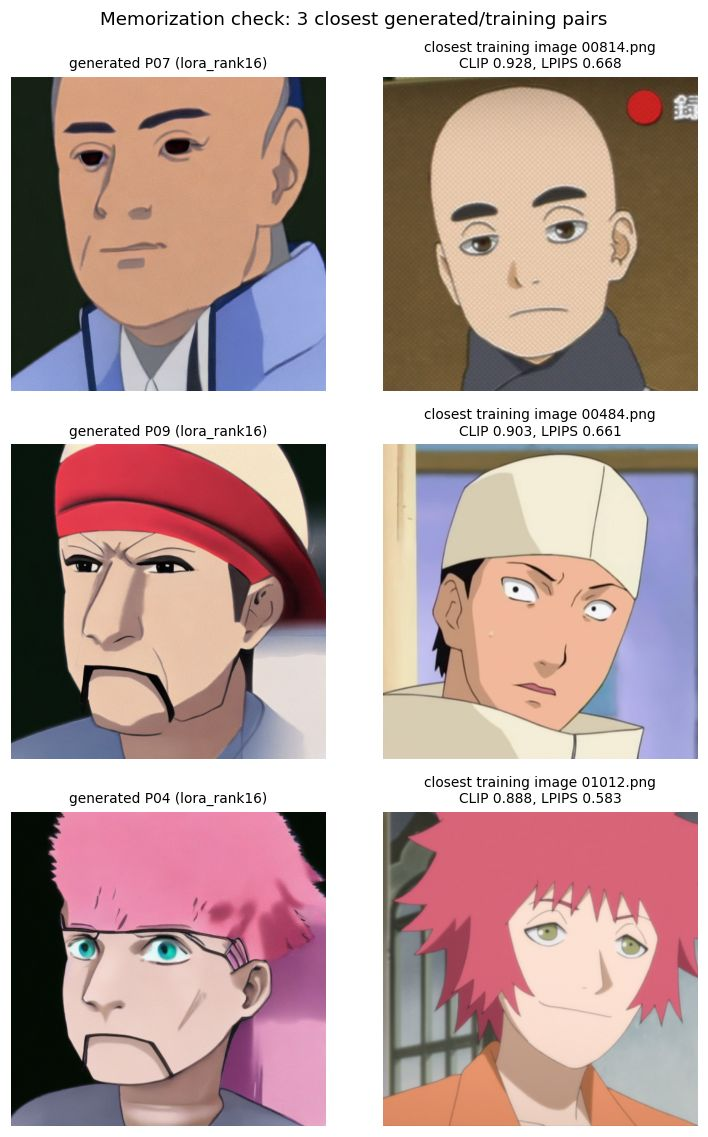

saved: /content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/results/figures/memorization_top3_generated_vs_train.png


In [11]:
train_emb = clip_image_embeddings([str(p) for p in train_paths])
test_nn = (clip_image_embeddings([str(p) for p in test_paths]) @ train_emb.T).max(1).values.cpu().numpy()
heldout_p95 = float(np.percentile(test_nn, 95))

mem_rows = []
for m in [FINAL_MODEL, "base"]:
    sel = gen[(gen.model == m) & (gen.category == "in_domain") & (gen.seed == 0)].sort_values("prompt_id")
    sims = clip_image_embeddings(list(sel["path"])) @ train_emb.T
    vals, idx = torch.topk(sims, 3, dim=1)
    for (_, r), v_row, i_row in zip(sel.iterrows(), vals.tolist(), idx.tolist()):
        for rank, (v, j) in enumerate(zip(v_row, i_row), 1):
            mem_rows.append({"model": m, "prompt_id": r.prompt_id, "generated_image": r.file_name, "rank": rank,
                             "training_image": train_paths[j].name, "clip_similarity": v,
                             "share_heldout_real_at_least_this_close": float((test_nn >= v).mean()),
                             "lpips_to_training_image": lpips_distance(r.path, train_paths[j]) if rank == 1 else np.nan})
memorization = pd.DataFrame(mem_rows)
memorization.to_csv(RESULTS_DIR / "memorization_generated_vs_train.csv", index=False)

top1 = memorization[memorization["rank"] == 1]
final_top1 = top1[top1.model == FINAL_MODEL].sort_values("clip_similarity", ascending=False)
closest3 = final_top1.head(3)
mem_summary = {
    "heldout_real_nn_similarity_median": float(np.median(test_nn)),
    "heldout_real_nn_similarity_p95": heldout_p95,
    "final_max_similarity": float(final_top1.clip_similarity.max()),
    "final_mean_top1_similarity": float(final_top1.clip_similarity.mean()),
    "base_mean_top1_similarity": float(top1[top1.model == "base"].clip_similarity.mean()),
    "final_generations_above_heldout_p95": int((final_top1.clip_similarity > heldout_p95).sum()),
    "final_min_lpips_to_nearest_training_image": float(final_top1.lpips_to_training_image.min()),
}
(RESULTS_DIR / "memorization_summary_v2.json").write_text(json.dumps(mem_summary, indent=2))

print(f"Top-1 training match for each of the 10 in-domain generations of {FINAL_MODEL}:")
display(final_top1[["prompt_id", "training_image", "clip_similarity", "share_heldout_real_at_least_this_close",
                    "lpips_to_training_image"]].round(4))
print(json.dumps(mem_summary, indent=2))

fig, ax = plt.subplots(3, 2, figsize=(7, 10.5))
for k, (_, r) in enumerate(closest3.iterrows()):
    ax[k, 0].imshow(Image.open(GENERATED_DIR / r.generated_image))
    ax[k, 0].set_title(f"generated {r.prompt_id} ({FINAL_MODEL})", fontsize=9)
    ax[k, 1].imshow(Image.open(TRAIN_DIR / r.training_image))
    ax[k, 1].set_title(f"closest training image {r.training_image}\nCLIP {r.clip_similarity:.3f}, "
                       f"LPIPS {r.lpips_to_training_image:.3f}", fontsize=9)
    ax[k, 0].axis("off"); ax[k, 1].axis("off")
fig.suptitle("Memorization check: 3 closest generated/training pairs")
fig.tight_layout()
save_and_show(fig, "memorization_top3_generated_vs_train", width=600)

## 2.4.1 Failure modes

Chosen from the numbers, not by hand: the out-of-domain prompt where the final run loses the most CLIP
score against the base model, the compositional prompt with the lowest CLIP score for the final run, every
image blocked by the NSFW filter (shown as a black tile), and the prompt where the final run's two seeds are
most alike (lowest LPIPS).

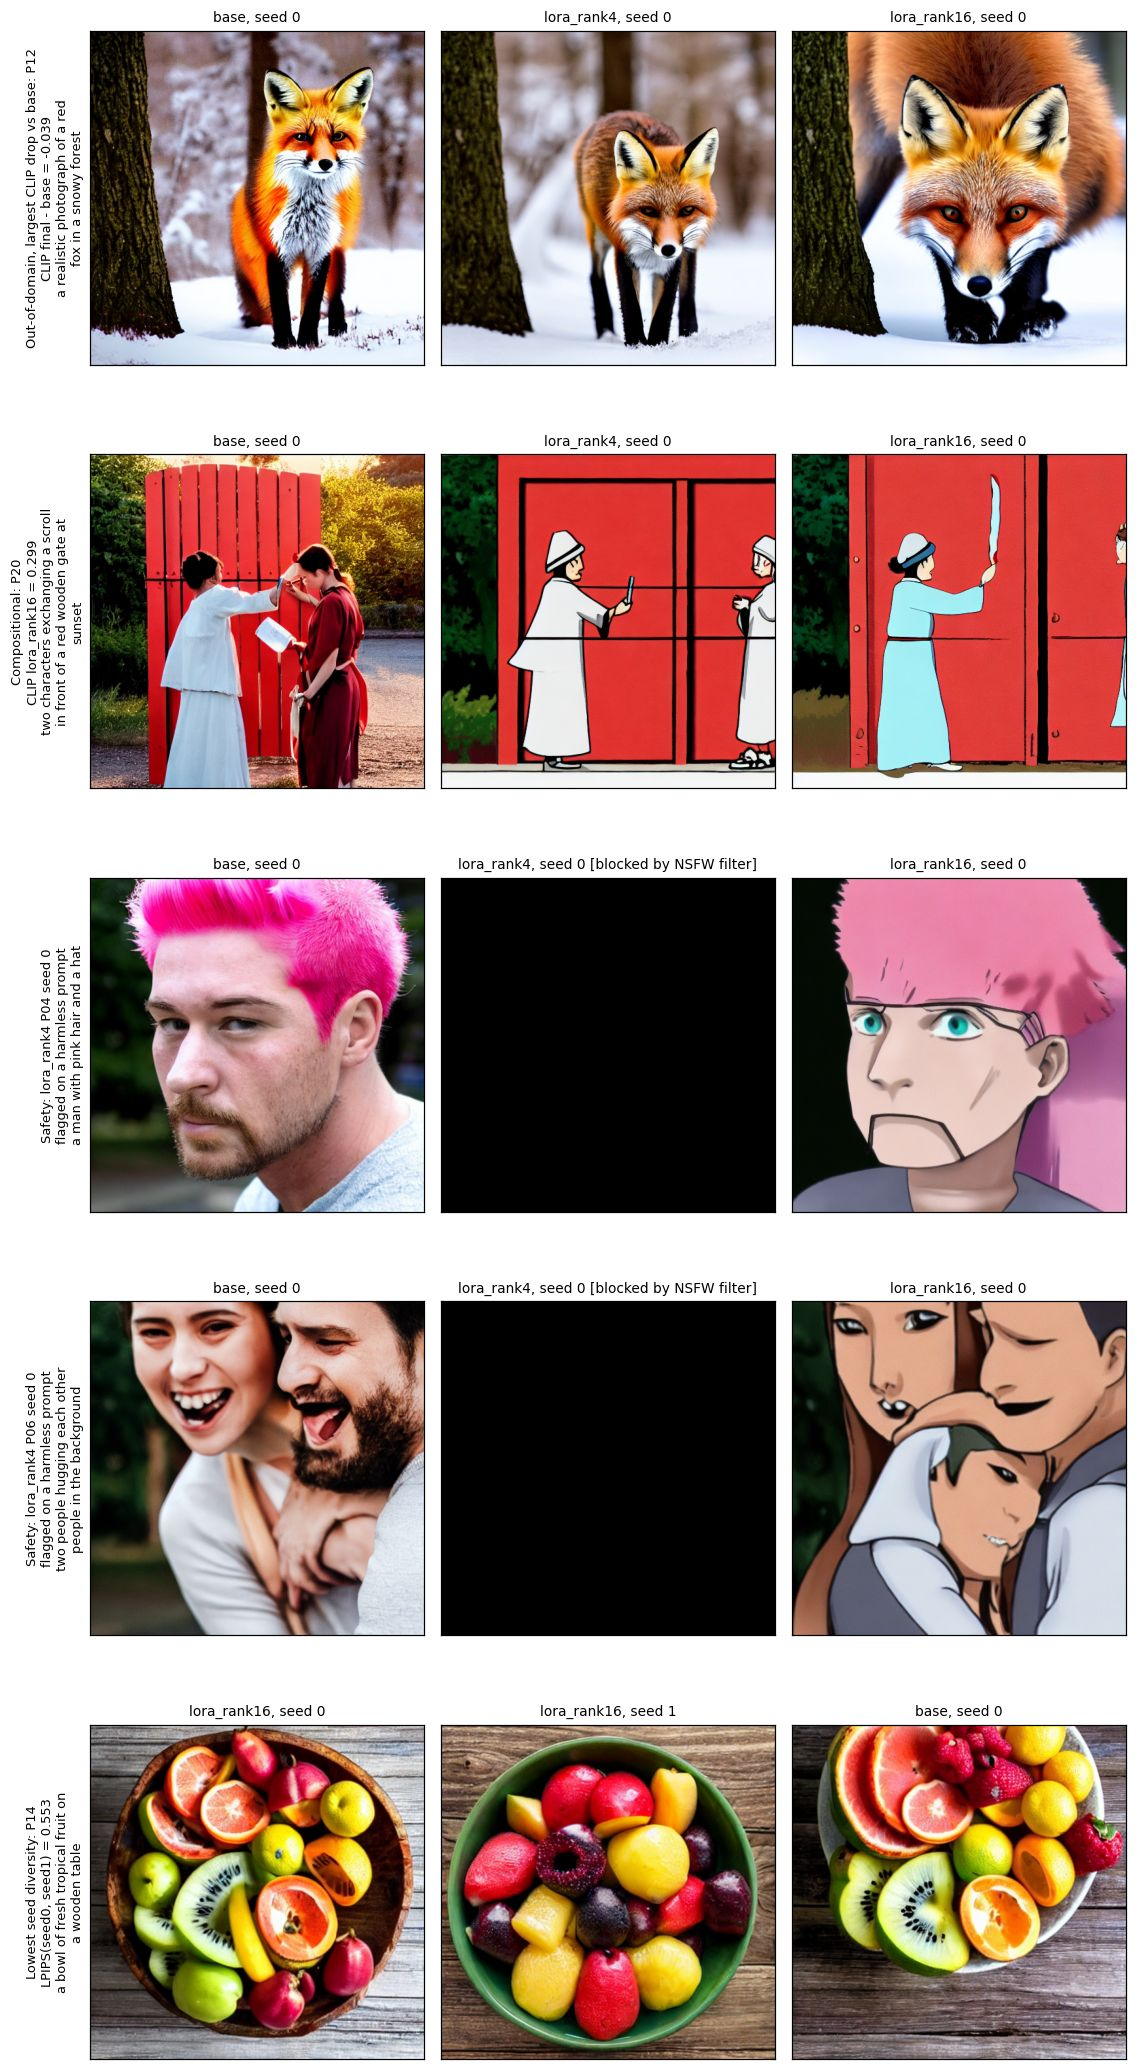

saved: /content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/results/figures/failure_modes_v2.png


,failure_mode,prompt_id,metric,value
0,out_of_domain_largest_clip_drop,P12,clip_final_minus_base,-0.0394
1,compositional_binding,P20,clip_lora_rank16,0.2993
2,low_seed_diversity,P14,lpips_seed_distance,0.5527
3,nsfw_false_positive,P04,lora_rank4_seed0_flagged,1.0000
4,nsfw_false_positive,P06,lora_rank4_seed0_flagged,1.0000


Per-prompt CLIP scores, final run vs base:


model,prompt_id,category,base,lora_rank16,lora_rank4,final_minus_base
0,P01,in_domain,0.3473,0.3303,0.3330,-0.0171
1,P02,in_domain,0.2401,0.2457,0.2464,0.0056
2,P03,in_domain,0.3357,0.3116,0.3228,-0.0242
3,P04,in_domain,0.3350,0.3246,0.3188,-0.0104
4,P05,in_domain,0.2741,0.2682,0.2681,-0.0059
5,P06,in_domain,0.2578,0.2773,0.2715,0.0195
6,P07,in_domain,0.3088,0.2677,0.2629,-0.0411
7,P08,in_domain,0.2790,0.2722,0.2766,-0.0068
8,P09,in_domain,0.2787,0.2878,0.2808,0.0091
9,P10,in_domain,0.2960,0.2797,0.3041,-0.0162


In [12]:
clip_wide = clip_scores.pivot_table(index=["prompt_id", "category"], columns="model", values="clip_score",
                                   aggfunc="mean").reset_index()
clip_wide["final_minus_base"] = clip_wide[FINAL_MODEL] - clip_wide["base"]
fm_ood = clip_wide[clip_wide.category == "out_of_domain"].sort_values("final_minus_base").iloc[0]
fm_comp = clip_wide[clip_wide.category == "compositional"].sort_values(FINAL_MODEL).iloc[0]
fm_div = lpips_scores[lpips_scores.model == FINAL_MODEL].sort_values("lpips_seed_distance").iloc[0]
fm_nsfw = safety_v2[safety_v2.nsfw_flagged]

def tile(model, pid, seed):
    if flagged_lookup.get((model, pid, int(seed))):
        return Image.new("RGB", (512, 512), "black"), " [blocked by NSFW filter]"
    return Image.open(GENERATED_DIR / model / f"{pid}_seed{seed}.png").convert("RGB"), ""

rows_spec = [
    (f"Out-of-domain, largest CLIP drop vs base: {fm_ood.prompt_id}\nCLIP final - base = {fm_ood.final_minus_base:+.3f}",
     [(m, fm_ood.prompt_id, 0) for m in MODELS]),
    (f"Compositional: {fm_comp.prompt_id}\nCLIP {FINAL_MODEL} = {fm_comp[FINAL_MODEL]:.3f}",
     [(m, fm_comp.prompt_id, 0) for m in MODELS]),
]
for r in fm_nsfw.itertuples():
    rows_spec.append((f"Safety: {r.model} {r.prompt_id} seed {r.seed}\nflagged on a harmless prompt",
                      [(m, r.prompt_id, r.seed) for m in MODELS]))
rows_spec.append((f"Lowest seed diversity: {fm_div.prompt_id}\nLPIPS(seed0, seed1) = {fm_div.lpips_seed_distance:.3f}",
                  [(FINAL_MODEL, fm_div.prompt_id, 0), (FINAL_MODEL, fm_div.prompt_id, 1), ("base", fm_div.prompt_id, 0)]))

fig, ax = plt.subplots(len(rows_spec), 3, figsize=(10.5, 3.9 * len(rows_spec)))
for i, (label, cells) in enumerate(rows_spec):
    for j, (m, pid, s) in enumerate(cells):
        im, note = tile(m, pid, s)
        ax[i, j].imshow(im); ax[i, j].set_xticks([]); ax[i, j].set_yticks([])
        ax[i, j].set_title(f"{m}, seed {s}{note}", fontsize=9)
    ax[i, 0].set_ylabel(label + "\n" + textwrap.fill(prompt_text[cells[0][1]], 34), fontsize=8.5)
fig.tight_layout()
save_and_show(fig, "failure_modes_v2")

failure_table = pd.DataFrame(
    [{"failure_mode": "out_of_domain_largest_clip_drop", "prompt_id": fm_ood.prompt_id, "metric": "clip_final_minus_base",
      "value": fm_ood.final_minus_base},
     {"failure_mode": "compositional_binding", "prompt_id": fm_comp.prompt_id, "metric": f"clip_{FINAL_MODEL}",
      "value": fm_comp[FINAL_MODEL]},
     {"failure_mode": "low_seed_diversity", "prompt_id": fm_div.prompt_id, "metric": "lpips_seed_distance",
      "value": fm_div.lpips_seed_distance}]
    + [{"failure_mode": "nsfw_false_positive", "prompt_id": r.prompt_id, "metric": f"{r.model}_seed{r.seed}_flagged",
        "value": 1.0} for r in fm_nsfw.itertuples()])
failure_table.to_csv(RESULTS_DIR / "failure_modes_v2.csv", index=False)
display(failure_table.round(4))
print("Per-prompt CLIP scores, final run vs base:")
display(clip_wide.round(4))

## Results table (baseline vs both runs)

One table with the four required measurements: primary (KID, CLIP), secondary (LPIPS diversity), human
evaluation (blinded win rate of the final run against the base model) and efficiency (GPU-hours and peak
GPU memory per training run, from `training_summary.csv` written by `p2_finetune.ipynb`).

In [13]:
k = kid_v2.set_index("model")
ts = training_summary.set_index("run")
flags = safety_v2.groupby("model")["nsfw_flagged"].sum()
rows = []
for m in MODELS:
    is_lora = m in ts.index
    rows.append({
        "model": m,
        "KID in-domain (lower better)": f"{k.loc[m, 'kid_mean']:.4f} ± {k.loc[m, 'kid_std']:.4f}",
        "CLIP score, 20 prompts": round(float(clip_scores[clip_scores.model == m].clip_score.mean()), 4),
        "CLIP score, in-domain": round(float(clip_scores[(clip_scores.model == m) & (clip_scores.category == "in_domain")].clip_score.mean()), 4),
        "LPIPS seed diversity": round(float(lpips_scores[lpips_scores.model == m].lpips_seed_distance.mean()), 4),
        "Human win rate vs base (excl. ties)": ("reference" if m == "base" else
            f"{human_stats['pooled_final_win_rate_excl_ties']:.1%}" if m == FINAL_MODEL else "not rated"),
        "NSFW flagged / 40": int(flags.get(m, 0)),
        "Training GPU-hours": round(float(ts.loc[m, "gpu_hours"]), 3) if is_lora else 0,
        "Peak GPU memory (GiB)": round(float(ts.loc[m, "peak_gpu_memory_gib"]), 2) if is_lora else "-",
        "Trainable parameters": int(ts.loc[m, "trainable_parameters"]) if is_lora else 0,
    })
results_table = pd.DataFrame(rows)
results_table.to_csv(RESULTS_DIR / "part2_results_table_v2.csv", index=False)
(RESULTS_DIR / "part2_results_table_v2.md").write_text(to_markdown(results_table) + "\n")
display(results_table)
print(to_markdown(results_table))

,model,KID in-domain (lower better),"CLIP score, 20 prompts","CLIP score, in-domain",LPIPS seed diversity,Human win rate vs base (excl. ties),NSFW flagged / 40,Training GPU-hours,Peak GPU memory (GiB),Trainable parameters
0,base,0.1420 ± 0.0260,0.3126,0.2953,0.6902,reference,0,0.000,-,0
1,lora_rank4,0.0336 ± 0.0155,0.3067,0.2885,0.6924,not rated,2,0.812,6.15,797184
2,lora_rank16,0.0351 ± 0.0162,0.3037,0.2865,0.6761,42.6%,0,0.808,6.17,3188736


| model | KID in-domain (lower better) | CLIP score, 20 prompts | CLIP score, in-domain | LPIPS seed diversity | Human win rate vs base (excl. ties) | NSFW flagged / 40 | Training GPU-hours | Peak GPU memory (GiB) | Trainable parameters |
|---|---|---|---|---|---|---|---|---|---|
| base | 0.1420 ± 0.0260 | 0.3126 | 0.2953 | 0.6902 | reference | 0 | 0.0 | - | 0 |
| lora_rank4 | 0.0336 ± 0.0155 | 0.3067 | 0.2885 | 0.6924 | not rated | 2 | 0.812 | 6.15 | 797184 |
| lora_rank16 | 0.0351 ± 0.0162 | 0.3037 | 0.2865 | 0.6761 | 42.6% | 0 | 0.808 | 6.17 | 3188736 |


In [14]:
# Which run to choose: the facts the decision rests on
lora_runs = ["lora_rank4", "lora_rank16"]
kid_gap = k.loc["lora_rank16", "kid_mean"] - k.loc["lora_rank4", "kid_mean"]
kid_noise = max(k.loc["lora_rank16", "kid_std"], k.loc["lora_rank4", "kid_std"])
facts = {
    "kid_gap_r16_minus_r4": kid_gap, "kid_subset_std": kid_noise,
    "kid_gap_within_noise": bool(abs(kid_gap) <= kid_noise),
    "kid_reduction_vs_base_r4": 1 - k.loc["lora_rank4", "kid_mean"] / k.loc["base", "kid_mean"],
    "kid_reduction_vs_base_r16": 1 - k.loc["lora_rank16", "kid_mean"] / k.loc["base", "kid_mean"],
    "nsfw_flags": {m: int(flags.get(m, 0)) for m in lora_runs},
    "clip_r16_minus_r4": float(clip_scores[clip_scores.model == "lora_rank16"].clip_score.mean()
                               - clip_scores[clip_scores.model == "lora_rank4"].clip_score.mean()),
    "lpips_r16_minus_r4": float(lpips_scores[lpips_scores.model == "lora_rank16"].lpips_seed_distance.mean()
                                - lpips_scores[lpips_scores.model == "lora_rank4"].lpips_seed_distance.mean()),
    "human_final_win_rate_excl_ties": human_stats["pooled_final_win_rate_excl_ties"],
}
clean_runs = [m for m in lora_runs if facts["nsfw_flags"][m] == 0]
if len(clean_runs) == 1:
    recommended, reason = clean_runs[0], "it is the only run with no NSFW-flagged outputs on the fixed prompts"
else:
    recommended = min(lora_runs, key=lambda m: k.loc[m, "kid_mean"])
    reason = "both runs pass the safety filter equally, so the lower in-domain KID decides"
facts.update({"recommended_final_run": recommended, "reason": reason})
(RESULTS_DIR / "final_run_decision.json").write_text(json.dumps(facts, indent=2, default=float))
print(json.dumps(facts, indent=2, default=float))
if recommended != FINAL_MODEL:
    print(f"NOTE: the rule recommends {recommended}, but the human evaluation and model card use {FINAL_MODEL}. "
          "Either justify keeping it in the text below, or set FINAL_MODEL and redo the human evaluation.")

{
  "kid_gap_r16_minus_r4": 0.0015175305306911469,
  "kid_subset_std": 0.01616360992193222,
  "kid_gap_within_noise": true,
  "kid_reduction_vs_base_r4": 0.7635964116825192,
  "kid_reduction_vs_base_r16": 0.7529077254705384,
  "nsfw_flags": {
    "lora_rank4": 2,
    "lora_rank16": 0
  },
  "clip_r16_minus_r4": -0.002904832363128662,
  "lpips_r16_minus_r4": -0.016251656413078353,
  "human_final_win_rate_excl_ties": 0.42592592592592593,
  "recommended_final_run": "lora_rank16",
  "reason": "it is the only run with no NSFW-flagged outputs on the fixed prompts"
}


### Final run choice

*(Check this paragraph against the printed facts above after each re-run.)*

We select **LoRA rank 16** as the final run. Both adapters learn the Naruto domain: in-domain KID drops
sharply against the base model for both, and the gap between rank 4 and rank 16 is small compared with the
KID spread over subsets, so KID alone does not separate them. Rank 4 is slightly better on CLIP score and
seed diversity, but the margins are small. The deciding factor is safety: on the same 40 prompts/seeds,
rank 16 produced no image flagged by the NSFW checker while rank 4 did, on prompts that ask for nothing
unsafe. Both runs cost the same GPU time and memory.

The blinded human evaluation shows the limitation of this choice. The final run does not beat the base
model on the combined "domain style + prompt match" judgement, because it pulls every prompt towards the
anime style and loses detail on out-of-domain and compositional prompts (see the failure modes). The
adapter is therefore a good *domain-style* generator, the role it plays in Part 3, and not a general
text-to-image replacement for the base model.

## Model cards and released image dataset (Hugging Face)

The model card is generated from the numbers computed above (no typed numbers). The released image
dataset uses the Hugging Face `imagefolder` layout: one `metadata.csv` at the root with `file_name`,
model, prompt, seed and sampler settings; NSFW-flagged images are excluded.

In [15]:
from huggingface_hub import hf_hub_download
scheduler_name = json.loads(Path(hf_hub_download(MODEL_NAME, "scheduler/scheduler_config.json")).read_text())["_class_name"]
GEN_STEPS = int(gen.steps.iloc[0]); GUIDANCE = float(gen.guidance_scale.iloc[0])

def model_card(run):
    r = ts.loc[run]
    table = to_markdown(results_table)
    return f"""---
license: creativeml-openrail-m
base_model: {MODEL_NAME}
datasets:
- {DATASET_NAME}
library_name: diffusers
pipeline_tag: text-to-image
tags:
- text-to-image
- stable-diffusion
- lora
- diffusers
---

# DATA266 Lab 2 Part 2: Naruto-style LoRA (rank {int(r['rank'])}){' - final run' if run == FINAL_MODEL else ''}

LoRA adapter for the UNet of `{MODEL_NAME}` that generates images in the style of the Naruto anime.
Course project (SJSU DATA 266), non-commercial research use only.

## Base model
`{MODEL_NAME}` at 512x512. Only the UNet attention projections are adapted; the text encoder and VAE are frozen.

## Data
`{DATASET_NAME}`: {cleaning_report['original_count']} anime frames with BLIP captions. {cleaning_report['removed_corrupt']} corrupt and
{cleaning_report['removed_duplicate']} exact-duplicate images were removed; split 90/10 with seed {cleaning_report['split_seed']} into
{cleaning_report['train_count']} training and {cleaning_report['test_count']} held-out test images. A perceptual-hash audit found
{audit['test_images_with_near_duplicate_in_train']} test image(s) with a near-duplicate in the training set.

## Training settings
| setting | value |
|---|---|
| method | LoRA, rank {int(r['rank'])} (UNet only) |
| trainable parameters | {int(r['trainable_parameters']):,} |
| steps | {int(r['steps'])} |
| batch size x gradient accumulation | {int(r['batch_size'])} x 4 |
| learning rate / schedule | {r['learning_rate']} constant, no warm-up |
| precision / optimizer | fp16 mixed precision, 8-bit AdamW, gradient checkpointing |
| augmentation | center crop, random horizontal flip |
| seed | {SEED} |
| hardware / time | 1x Tesla T4, {r['gpu_hours']:.2f} GPU-hours, peak {r['peak_gpu_memory_gib']:.2f} GiB |

## Results
20 fixed prompts (10 in-domain from held-out captions, 5 out-of-domain, 5 compositional), seeds 0 and 1,
{GEN_STEPS} steps of {scheduler_name}, guidance {GUIDANCE}. KID: 20 in-domain generations vs {len(test_paths)} test images.

{table}

## Limitations
* Strong style prior: out-of-domain prompts (photographs, paintings) are pulled towards the anime style.
* Weak on composition: counting, colour binding and spatial relations across several characters.
* BLIP captions are short and generic; caption terms are skewed towards male characters.
* KID is computed from only 20 generated images and is noisy.

## Safety
* All generations pass the Stable Diffusion safety checker before release; flagged images were removed.
  Flagged on our 40 evaluation images: {int(flags.get(run, 0))}.
* Memorization check (final run): the 10 in-domain generations were matched to their nearest training images
  by CLIP similarity; {mem_summary['final_generations_above_heldout_p95']} of 10 are closer than the 95th percentile of
  real unseen frames, and the smallest LPIPS distance to a training image is {mem_summary['final_min_lpips_to_nearest_training_image']:.3f}.

## License and intended use
The adapter is derived from Stable Diffusion v1.5 and is distributed under the CreativeML OpenRAIL-M licence,
including its use restrictions. The training images show copyrighted Naruto characters: use the adapter and
its outputs for non-commercial research and teaching only.

## Use
```python
import torch
from diffusers import StableDiffusionPipeline
pipe = StableDiffusionPipeline.from_pretrained("{MODEL_NAME}", torch_dtype=torch.float16).to("cuda")
pipe.load_lora_weights("{RANK16_REPO if run == 'lora_rank16' else RANK4_REPO}")
image = pipe("a man with pink hair and a hat", num_inference_steps={GEN_STEPS}, guidance_scale={GUIDANCE}).images[0]
```
"""

cards = {"lora_rank16": (RANK16_REPO, model_card("lora_rank16")), "lora_rank4": (RANK4_REPO, model_card("lora_rank4"))}
for run, (repo, text) in cards.items():
    (RESULTS_DIR / f"README_{run}_model_card.md").write_text(text)
print(cards[FINAL_MODEL][1])

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

---
license: creativeml-openrail-m
base_model: stable-diffusion-v1-5/stable-diffusion-v1-5
datasets:
- lambdalabs/naruto-blip-captions
library_name: diffusers
pipeline_tag: text-to-image
tags:
- text-to-image
- stable-diffusion
- lora
- diffusers
---

# DATA266 Lab 2 Part 2: Naruto-style LoRA (rank 16) - final run

LoRA adapter for the UNet of `stable-diffusion-v1-5/stable-diffusion-v1-5` that generates images in the style of the Naruto anime.
Course project (SJSU DATA 266), non-commercial research use only.

## Base model
`stable-diffusion-v1-5/stable-diffusion-v1-5` at 512x512. Only the UNet attention projections are adapted; the text encoder and VAE are frozen.

## Data
`lambdalabs/naruto-blip-captions`: 1221 anime frames with BLIP captions. 0 corrupt and
0 exact-duplicate images were removed; split 90/10 with seed 266 into
1098 training and 123 held-out test images. A perceptual-hash audit found
1 test image(s) with a near-duplicate in the training set.

## Training settings
| sett

In [16]:
RELEASE_DIR = PROJECT_DIR / "outputs/release_hf"
if RELEASE_DIR.exists():
    shutil.rmtree(RELEASE_DIR)
release = gen.merge(safety_v2[["file_name", "nsfw_flagged"]], on="file_name")
release = release[~release.nsfw_flagged].copy()
for m in MODELS:
    (RELEASE_DIR / m).mkdir(parents=True, exist_ok=True)
for r in release.itertuples():
    shutil.copy2(r.path, RELEASE_DIR / r.file_name)
release["scheduler"] = scheduler_name
release_meta = release[["file_name", "model", "prompt_id", "category", "prompt", "seed", "steps", "guidance_scale", "scheduler"]]
release_meta.to_csv(RELEASE_DIR / "metadata.csv", index=False)
(RELEASE_DIR / "README.md").write_text(f"""---
license: other
tags:
- text-to-image
- stable-diffusion
- lora
---
# DATA266 Lab 2 Part 2: generated images (safety-filtered)

Images from the base `{MODEL_NAME}` model and two Naruto LoRA adapters ({RANK4_REPO}, {RANK16_REPO}) for
20 fixed prompts and seeds 0 and 1, all with {GEN_STEPS} {scheduler_name} steps and guidance {GUIDANCE}.
`metadata.csv` lists the model, prompt, seed and sampler settings of every file. Images flagged by the
Stable Diffusion safety checker are not included ({int(len(gen) - len(release))} removed).
Non-commercial research use only: the images depict copyrighted anime characters.
""")
print("Release images per model:", release.groupby("model").size().to_dict())

if UPLOAD_TO_HUB:
    from huggingface_hub import login, upload_folder
    try:
        from google.colab import userdata
        login(token=userdata.get("HF_TOKEN"), add_to_git_credential=False)   # Colab secret named HF_TOKEN
    except Exception:
        login(token=os.environ["HF_TOKEN"], add_to_git_credential=False)
    for run, (repo, text) in cards.items():
        api.upload_file(path_or_fileobj=text.encode(), path_in_repo="README.md", repo_id=repo, repo_type="model",
                        commit_message="Model card with results, limitations and licence")
    upload_folder(repo_id=SAFE_DATASET_REPO, repo_type="dataset", folder_path=str(RELEASE_DIR),
                  delete_patterns=["*/metadata.csv", "safe_generation_manifest.csv"],
                  commit_message="Root metadata.csv with file_name/model/prompt/seed/sampler; dataset card")
    print("Uploaded model cards and", f"https://huggingface.co/datasets/{SAFE_DATASET_REPO}")
else:
    print("UPLOAD_TO_HUB is False: nothing pushed.")

Release images per model: {'base': 40, 'lora_rank16': 40, 'lora_rank4': 38}


No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.


Uploaded model cards and https://huggingface.co/datasets/Anushka1202/data266-lab2-part2-generated-images-safe


In [17]:
# The first (unfiltered) dataset repo still contains the images flagged above.
flagged_files = [f"generated/{f}" for f in safety_v2.loc[safety_v2.nsfw_flagged, "file_name"]]
print("Flagged files in", UNFILTERED_DATASET_REPO, ":", flagged_files)
if CLEAN_UNFILTERED_REPO and flagged_files:
    remote = set(api.list_repo_files(UNFILTERED_DATASET_REPO, repo_type="dataset"))
    for f in flagged_files:
        if f not in remote:
            print("already removed:", f)
            continue
        try:
            api.delete_file(path_in_repo=f, repo_id=UNFILTERED_DATASET_REPO, repo_type="dataset",
                            commit_message=f"Remove NSFW-flagged image {f}")
            print("deleted", f)
        except Exception as e:
            print("could not delete", f, "-", type(e).__name__, e)
else:
    print("CLEAN_UNFILTERED_REPO is False: nothing deleted.")

Flagged files in Anushka1202/data266-lab2-part2-generated-images : ['generated/lora_rank4/P04_seed0.png', 'generated/lora_rank4/P06_seed0.png']
already removed: generated/lora_rank4/P04_seed0.png
already removed: generated/lora_rank4/P06_seed0.png


In [18]:
# Artifacts written by this notebook
written = sorted(p.relative_to(PROJECT_DIR).as_posix() for p in RESULTS_DIR.rglob("*")
                 if p.is_file() and p.stat().st_mtime > time.time() - 6 * 3600)
print("\n".join(written))

results/README_lora_rank16_model_card.md
results/README_lora_rank4_model_card.md
results/clip_scores.csv
results/dataset_description_v2.json
results/failure_modes_v2.csv
results/figures/data_near_duplicates.png
results/figures/data_near_duplicates_preview.jpg
results/figures/failure_modes_v2.png
results/figures/failure_modes_v2_preview.jpg
results/figures/grid_base_r4_r16_part1.png
results/figures/grid_base_r4_r16_part1_preview.jpg
results/figures/grid_base_r4_r16_part2.png
results/figures/grid_base_r4_r16_part2_preview.jpg
results/figures/memorization_top3_generated_vs_train.png
results/figures/memorization_top3_generated_vs_train_preview.jpg
results/final_run_decision.json
results/human_eval/human_eval_sheet_all_25.pdf
results/human_evaluation_by_category_v2.csv
results/human_evaluation_stats_v2.json
results/human_evaluation_summary_v2.csv
results/kid_scores_in_domain_v2.csv
results/lpips_scores.csv
results/memorization_generated_vs_train.csv
results/memorization_summary_v2.json
resu